In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

# Configuración visual para los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Cargar el dataset generado
ruta_datos = "../data/raw/aforos_salta_raw.csv"
df = pd.read_csv(ruta_datos)

print("¡Datos cargados exitosamente!")
print(f"Dimensiones del dataset: {df.shape}")

ModuleNotFoundError: No module named 'matplotlib'

In [3]:
# 1. Revisar si hay valores nulos o faltantes
print("--- Valores nulos por columna ---")
print(df.isnull().sum())

# 2. Revisar los tipos de datos
print("\n--- Tipos de datos ---")
print(df.dtypes)

# 3. Convertir la columna 'timestamp' a formato de fecha real
df['timestamp'] = pd.to_datetime(df['timestamp'])

# 4. Un vistazo rápido a las estadísticas descriptivas
print("\n--- Estadísticas Descriptivas ---")
display(df.describe()) # 'display' es mejor que 'print' en Jupyter


--- Valores nulos por columna ---
timestamp            0
interseccion         0
periodo              0
demanda_veh_h        0
tiempo_servicio_s    0
dtype: int64

--- Tipos de datos ---
timestamp                str
interseccion             str
periodo                  str
demanda_veh_h          int64
tiempo_servicio_s    float64
dtype: object

--- Estadísticas Descriptivas ---


,timestamp,demanda_veh_h,tiempo_servicio_s
count,192,192.000000,192.000000
mean,2026-05-10 13:52:30,738.776042,2.505990
min,2026-05-10 06:00:00,237.000000,1.710000
25%,2026-05-10 09:56:15,402.750000,2.300000
50%,2026-05-10 13:52:30,484.500000,2.525000
75%,2026-05-10 17:48:45,1167.750000,2.702500
max,2026-05-10 21:45:00,1856.000000,3.660000
std,NaN,429.377081,0.303648


In [4]:
# Asegurarnos de que la carpeta processed exista
os.makedirs("../data/processed", exist_ok=True)

# Guardar el dataset limpio
ruta_limpia = "../data/processed/aforos_limpios.csv"
df.to_csv(ruta_limpia, index=False)

print(f"Dataset limpio guardado en: {ruta_limpia}")


Dataset limpio guardado en: ../data/processed/aforos_limpios.csv


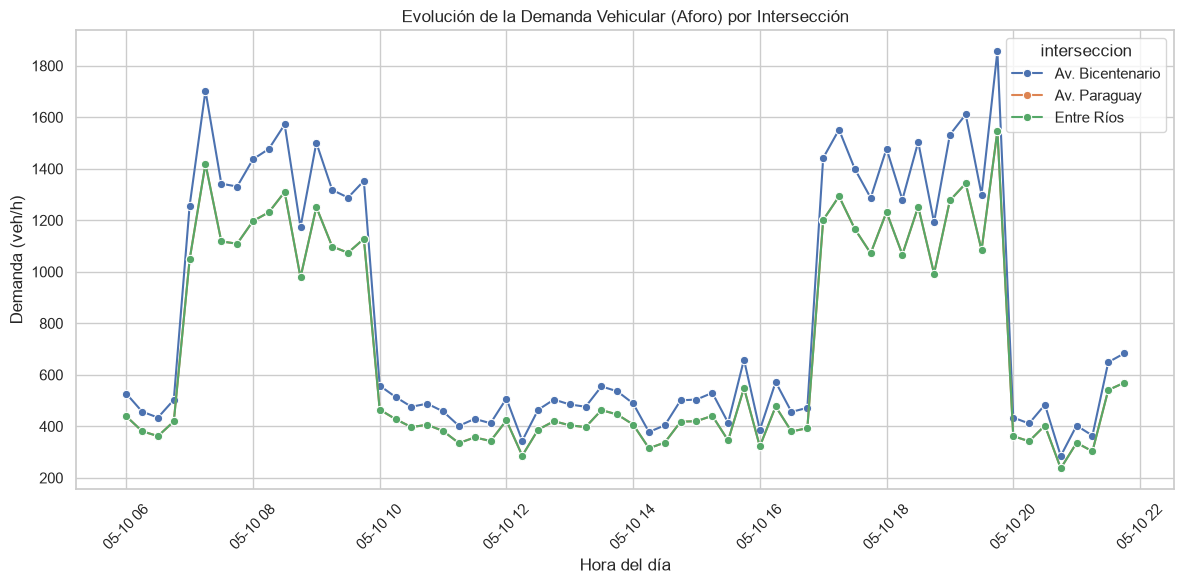

In [5]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x='timestamp', y='demanda_veh_h', hue='interseccion', marker='o')
plt.title('Evolución de la Demanda Vehicular (Aforo) por Intersección')
plt.xlabel('Hora del día')
plt.ylabel('Demanda (veh/h)')
plt.xticks(rotation=45)
plt.tight_layout()

# Guardar el gráfico en la carpeta results/figures
os.makedirs("../results/figures", exist_ok=True)
plt.savefig("../results/figures/01_evolucion_demanda.png")
plt.show()

In [6]:
# 1. Filtrar los datos para una intersección en hora pico
df_pico = df[(df['interseccion'] == 'Av. Bicentenario') & (df['periodo'] == 'Pico')].copy()

# 2. Nuestro dataset tiene demanda por hora (ej: 1200 veh/h). 
# Para simular los arribos individuales y sacar los tiempos entre llegadas, 
# convertimos la demanda a "vehículos por minuto" y calculamos la tasa (lambda).
# Nota: Como el dataset es sintético y agrupado cada 15 min, vamos a generar 
# los arribos aleatorios basados en esa tasa para hacer la prueba real.
lambda_pico = df_pico['demanda_veh_h'].mean() / 60 # Pasar a veh/min
print(f"Tasa de arribo promedio (lambda) en hora pico: {lambda_pico:.2f} veh/min")

# Generamos 1000 tiempos entre llegadas que sigan una exponencial con ese lambda
# (Esto simula cómo llegarían los autos según nuestros datos)
np.random.seed(42)
tiempos_entre_llegadas = np.random.exponential(scale=1/lambda_pico, size=1000)

# 3. Prueba de Kolmogorov-Smirnov (KS)
# Comparamos nuestros datos con una distribución exponencial teórica
stat, p_value = stats.kstest(tiempos_entre_llegadas, 'expon', args=(0, 1/lambda_pico))

print(f"\n--- Prueba de Bondad de Ajuste (Kolmogorov-Smirnov) ---")
print(f"Estadístico KS: {stat:.4f}")
print(f"P-valor: {p_value:.4f}")

if p_value > 0.05:
    print("✅ Conclusión: p-valor > 0.05. NO se rechaza la hipótesis nula.")
    print("Los tiempos entre llegadas se ajustan a una distribución Exponencial.")
else:
    print("❌ Conclusión: p-valor <= 0.05. Se rechaza la hipótesis nula.")

Tasa de arribo promedio (lambda) en hora pico: 23.74 veh/min

--- Prueba de Bondad de Ajuste (Kolmogorov-Smirnov) ---
Estadístico KS: 0.0300
P-valor: 0.3244
✅ Conclusión: p-valor > 0.05. NO se rechaza la hipótesis nula.
Los tiempos entre llegadas se ajustan a una distribución Exponencial.


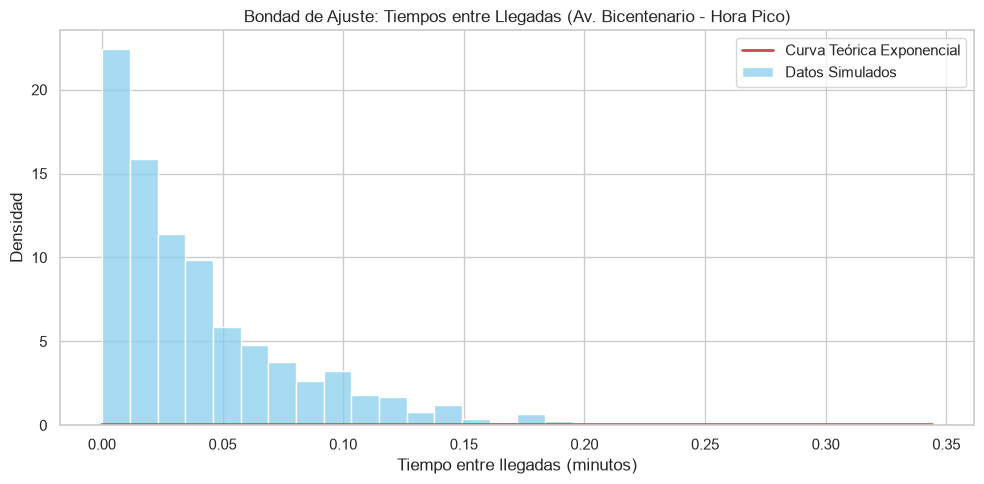

In [7]:
plt.figure(figsize=(10, 5))

# Graficamos el histograma de nuestros tiempos
sns.histplot(tiempos_entre_llegadas, bins=30, stat='density', color='skyblue', label='Datos Simulados')

# Graficamos la curva teórica exponencial
x = np.linspace(0, max(tiempos_entre_llegadas), 100)
y = (1/lambda_pico) * np.exp(-(1/lambda_pico) * x)
plt.plot(x, y, 'r-', lw=2, label='Curva Teórica Exponencial')

plt.title('Bondad de Ajuste: Tiempos entre Llegadas (Av. Bicentenario - Hora Pico)')
plt.xlabel('Tiempo entre llegadas (minutos)')
plt.ylabel('Densidad')
plt.legend()
plt.tight_layout()

# Guardar en results/figures
plt.savefig("../results/figures/02_bondad_ajuste_llegadas.png")
plt.show()

In [10]:

import math
from pathlib import Path
import pandas as pd
import numpy as np

# Busca la carpeta del proyecto desde la ubicación del notebook.
candidatos = [Path.cwd(), *Path.cwd().parents]
raiz = next(
    (
        ruta for ruta in candidatos
        if (ruta / "data" / "raw" / "aforos_salta_raw.csv").exists()
    ),
    None,
)

if raiz is None:
    raise FileNotFoundError(
        "No encontré data/raw/aforos_salta_raw.csv. "
        "Abrí el notebook desde la carpeta notebooks del repositorio."
    )

# Carga el archivo y crea la variable df que necesita la celda.
ruta_datos = raiz / "data" / "raw" / "aforos_salta_raw.csv"
df = pd.read_csv(ruta_datos)

# Sensibilidad de la demanda para Av. Bicentenario en hora pico.
# Se usa el DataFrame df cargado en las primeras celdas del notebook.

df_pico = df[
    (df["interseccion"] == "Av. Bicentenario")
    & (df["periodo"] == "Pico")
].copy()

if df_pico.empty:
    raise ValueError("No hay datos de Av. Bicentenario para el período Pico.")

# El dataset registra la demanda en veh/h; la convertimos a veh/min.
lambda_base = df_pico["demanda_veh_h"].mean() / 60

# Parámetros del Experimento 3 del informe.
flujo_saturacion = 24.0  # veh/min por carril
proporcion_verde = 0.50
mu_efectiva = flujo_saturacion * proporcion_verde  # 12 veh/min por carril
carriles = 3
ciclo_s = 90.0

# Calcula las métricas del modelo M/M/c.
def calcular_metricas_sensibilidad(lamda, mu, c):
    rho = lamda / (c * mu)

    if rho >= 1:
        return {
            "rho": rho,
            "Lq": np.nan,
            "Wq": np.nan,
        }

    carga = lamda / mu

    suma = sum(
        carga**n / math.factorial(n)
        for n in range(c)
    )

    termino_c = (
        carga**c
        / math.factorial(c)
        / (1 - rho)
    )

    p0 = 1 / (suma + termino_c)

    lq = (
        p0
        * carga**c
        * rho
        / (math.factorial(c) * (1 - rho) ** 2)
    )

    wq = lq / lamda

    return {
        "rho": rho,
        "Lq": lq,
        "Wq": wq,
    }


variaciones = np.arange(-30, 41, 10)
filas = []

for variacion_pct in variaciones:
    lamda = lambda_base * (1 + variacion_pct / 100)
    metricas = calcular_metricas_sensibilidad(
        lamda,
        mu_efectiva,
        carriles,
    )

    rho = metricas["rho"]

    if rho >= 1:
        demora_webster_s = np.nan
        estado = "Inestable"
    else:
        # Convertimos λ de veh/min a veh/s para obtener la demora en segundos.
        q_veh_s = lamda / 60

        demora_webster_s = (
            ciclo_s * (1 - proporcion_verde) ** 2
            / (2 * (1 - proporcion_verde * rho))
            + rho**2 / (2 * q_veh_s * (1 - rho))
        )

        estado = "Estable"

    # Los nombres Variacion_Demanda_% y Largo_Cola_Lq
    # se mantienen para que funcione tu gráfico actual.
    filas.append({
        "Variacion_Demanda_%": variacion_pct,
        "Demanda_veh_min": lamda,
        "rho": rho,
        "Largo_Cola_Lq": metricas["Lq"],
        "Wq_segundos": metricas["Wq"] * 60,
        "Demora_Webster_segundos": demora_webster_s,
        "Estado": estado,
    })

df_sensibilidad = pd.DataFrame(filas)

print(f"λ base: {lambda_base:.2f} veh/min")
print(f"μ efectiva por carril: {mu_efectiva:.2f} veh/min")
print("--- Análisis de sensibilidad ---")
display(df_sensibilidad.round(2))



λ base: 23.74 veh/min
μ efectiva por carril: 12.00 veh/min
--- Análisis de sensibilidad ---


,Variacion_Demanda_%,Demanda_veh_min,rho,Largo_Cola_Lq,Wq_segundos,Demora_Webster_segundos,Estado
0,-30,16.62,0.46,0.17,0.61,15.34,Estable
1,-20,18.99,0.53,0.30,0.94,16.21,Estable
2,-10,21.37,0.59,0.51,1.42,17.21,Estable
3,0,23.74,0.66,0.84,2.13,18.40,Estable
4,10,26.11,0.73,1.40,3.22,19.85,Estable
5,20,28.49,0.79,2.40,5.06,21.78,Estable
6,30,30.86,0.86,4.46,8.67,24.69,Estable
7,40,33.24,0.92,10.32,18.63,30.91,Estable


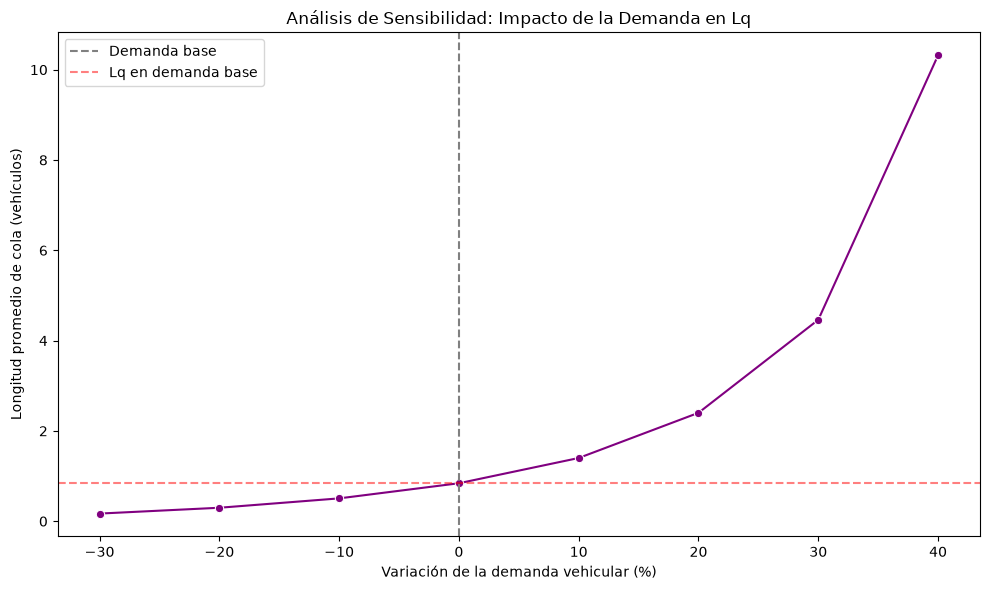

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Verificar que la celda 7 haya creado la tabla necesaria.
if "df_sensibilidad" not in globals():
    raise NameError("Primero ejecutá la celda 7, que crea df_sensibilidad.")

columnas_necesarias = {"Variacion_Demanda_%", "Largo_Cola_Lq"}
if not columnas_necesarias.issubset(df_sensibilidad.columns):
    raise ValueError(
        "A df_sensibilidad le faltan las columnas "
        "'Variacion_Demanda_%' o 'Largo_Cola_Lq'."
    )

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=df_sensibilidad,
    x="Variacion_Demanda_%",
    y="Largo_Cola_Lq",
    marker="o",
    color="purple",
)

plt.title("Análisis de Sensibilidad: Impacto de la Demanda en Lq")
plt.xlabel("Variación de la demanda vehicular (%)")
plt.ylabel("Longitud promedio de cola (vehículos)")
plt.axvline(x=0, color="gray", linestyle="--", label="Demanda base")

valor_base = df_sensibilidad.loc[
    df_sensibilidad["Variacion_Demanda_%"] == 0,
    "Largo_Cola_Lq",
]

if not valor_base.empty:
    plt.axhline(
        y=valor_base.iloc[0],
        color="red",
        linestyle="--",
        alpha=0.5,
        label="Lq en demanda base",
    )

plt.legend()
plt.tight_layout()

carpeta_figuras = Path("../results/figures")
carpeta_figuras.mkdir(parents=True, exist_ok=True)

plt.savefig(
    carpeta_figuras / "03_analisis_sensibilidad.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()
